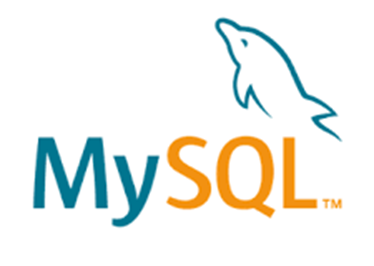

# Introdução ao MySQL com Python

#### Passo 1: Instalar bibliotecas

In [1]:
%pip install pymysql

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


#### Passo 2: Importar bibliotecas

In [2]:
import pymysql

#### Passo 3: Conectar no MySQL

In [3]:
# Cria conexão com banco de dados
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root"
)
cursor = conn.cursor()

#### Passo 4:  Criar banco

In [4]:
cursor.execute("CREATE DATABASE IF NOT EXISTS meubanco")
print("Banco criado com sucesso!")

Banco criado com sucesso!


#### Passo 5: Conferir no Workbench
- Abra o **MySQL Workbench**
- No painel esquerdo (Schemas), clique em Refresh
- Você deve ver o banco `meubanco`

#### Passo 6: Verificar conexão

In [5]:
# Encerrar conexão com banco de dados
conn.close()

In [6]:
# Testa se a conexão está ativa
if conn.open:
    print("Conexão ativa!")
else:
    print('Banco de dados desconectado')

Banco de dados desconectado


In [7]:
# Criar conexão 
if not conn.open:
    conn.ping(reconnect=True)

C:\Users\49048057809\AppData\Local\Temp\ipykernel_25828\628939375.py:3: DeprecationWarning: The 'reconnect' argument is deprecated. Create a new connection if you want to reconnect.
  conn.ping(reconnect=True)


In [8]:
# Verificar em qual banco está conectado
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

(None,)

In [9]:
# Verificar bancos existentes
cursor.execute("SHOW DATABASES;")
cursor.fetchall()

(('auracine',),
 ('hospital_db',),
 ('information_schema',),
 ('livraria_express',),
 ('meubanco',),
 ('mysql',),
 ('performance_schema',),
 ('sakila',),
 ('sistema_empresa',),
 ('sys',),
 ('techburguer',),
 ('techdelivery',),
 ('vidafit',),
 ('world',))

In [10]:
# Conectar ao banco existente
cursor.execute("USE meubanco")

0

In [11]:
# Verificar em qual banco está conectado
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

('meubanco',)

In [12]:
# Encerrar conexão com banco de dados
conn.close()

In [13]:
# Forma completa para conectar
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root",
    database="meubanco"  
)
cursor = conn.cursor()

In [14]:
# Verificar em qual banco está conectado
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

('meubanco',)

#### Passo 7: Criar tabela

In [15]:
# Conecta com banco de dados
cursor = conn.cursor()

# Cria Tabela
cursor.execute("""
CREATE TABLE IF NOT EXISTS produtos (
    id INT AUTO_INCREMENT PRIMARY KEY,
    titulo VARCHAR(255),
    preco DECIMAL(10,2),
    categoria VARCHAR(100)
)
""")
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


#### Passo 8: Inserir dados

In [16]:
dados = [
    ("Notebook Dell", 3500.00, "Eletrônicos"),
    ("Smartphone Samsung", 2100.00, "Eletrônicos"),
    ("Livro Python", 89.90, "Livros"),
    ("Monitor LG", 899.00, "Eletrônicos")
]
cursor.executemany("INSERT INTO produtos (titulo, preco, categoria) VALUES (%s, %s, %s)", dados)
conn.commit()
print("Dados inseridos!")

Dados inseridos!


In [17]:
# Encerrar conexão com banco de dados
conn.close()

#### Passo 9: Visualizar no Workbench
- Clique em `meubanco` → abra a aba de queries.

Rode: `SELECT * FROM produtos;`

#### Passo 9: inserindo novos dados pelo Workbench
Ainda no Workbench, rode:

`INSERT INTO produtos (titulo, preco, categoria)`

`VALUES ("Mouse Gamer", 199.90, "Eletrônicos");`

#### Passo 10: Consulta de teste no Python

In [18]:
# Conecta com Banco de dados
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root",
    database="meubanco"  
)
cursor = conn.cursor()

In [19]:
cursor.execute("SELECT * FROM produtos")
for row in cursor.fetchall():
    print(row)

(1, 'Notebook Dell', Decimal('3500.00'), 'Eletrônicos')
(2, 'Smartphone Samsung', Decimal('2100.00'), 'Eletrônicos')
(3, 'Livro Python', Decimal('89.90'), 'Livros')
(4, 'Monitor LG', Decimal('899.00'), 'Eletrônicos')


# Neste exercício exploramos Python e Workbench no mesmo banco MySQL
- O banco é o mesmo: Python e Workbench são apenas **duas portas de acesso**.
- Você pode **criar, inserir e consultar** dados em um ambiente e ver os resultados no outro.
- Isso mostra a importância de **separar a camada de aplicação (Python) da camada de dados (MySQL).**

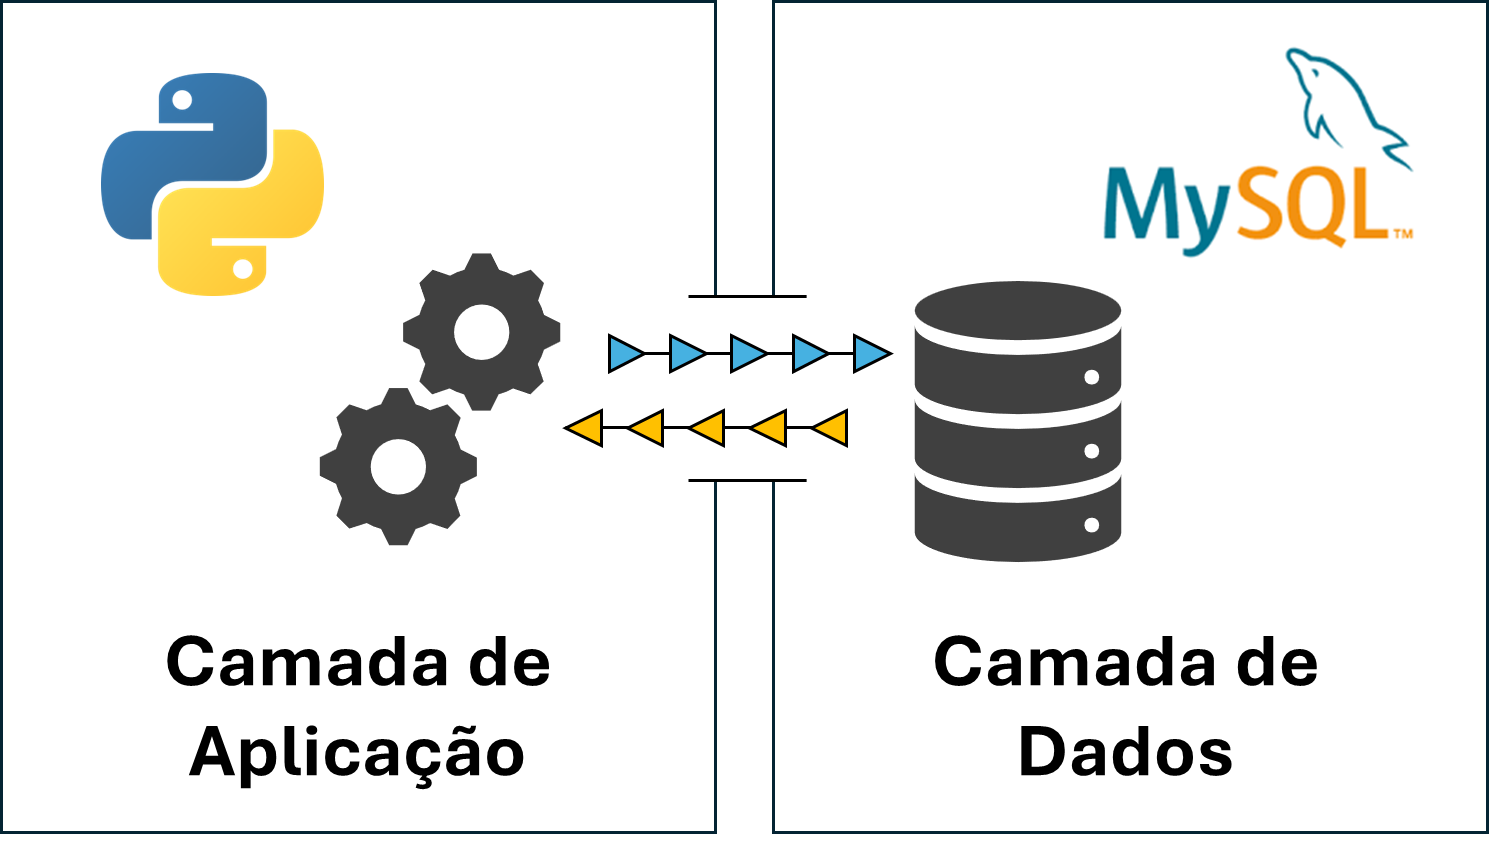

### Onde o banco de dados fica salvo? 

- Diferente do **SQLite** em que o banco é criado como **um arquivo** `.db` **no diretório atual** (mesma pasta do notebook/script)
- O **MySQL guarda os bancos em uma pasta interna do servido**. Geralmente em:
 
  `C:\ProgramData\MySQL\MySQL Server 8.0\Data\`
  
 **Atenção:** 
 - Essa pasta é oculta, tem que habilitar **Mostrar arquivos ocultos**
 - Você **não manipula diretamente esses arquivos**, sempre acessa via o servidor MySQL (Workbench, Python, terminal).

### Apagar o banco de dados

- Atenção! Esse comando apaga todo o banco de dados (tabelas, dados, índices, etc.).

- **Não há undo** – depois de rodar, não tem como recuperar a não ser que você tenha backup.

In [20]:
# Exclui banco de dados
cursor.execute("DROP DATABASE IF EXISTS meubanco")

# Salvar. commit() grava de forma definitiva as alterações feitas no banco de dados na transação atual
conn.commit()

# Fecha o canal de envio de comandos
cursor.close()

# Encerrar conexão com banco de dados
conn.close()

---
# Exercícios de fixação

> **Orientação:** execute cada exercício em sequência. Quando necessário, confira o resultado também no MySQL Workbench.


## Exercício 1: Conexão com o MySQL

Crie uma conexão com o servidor MySQL utilizando `pymysql.connect()`. Depois:

1. crie um cursor;
2. execute `SELECT DATABASE();`;
3. imprima o resultado;
4. verifique se a conexão está ativa.

**Objetivo:** praticar conexão, cursor e execução de uma consulta simples.


In [21]:
# Escreva sua solução aqui

conn = pymysql.connect(
    host = "localhost",
    user = "root",
    password = "root"
)

In [22]:
cursor = conn.cursor()

cursor.execute("SELECT DATABASE();")
cursor.fetchone()


(None,)

In [23]:
if conn.open:
    print("Conexão ativa!")
else:
    print('Banco de dados desconectado')

Conexão ativa!


## Exercício 2: Criando um banco para os exercícios

Crie um banco de dados chamado `loja_treinamento`, caso ele ainda não exista. Em seguida, selecione esse banco com o comando `USE` e confirme, por meio de `SELECT DATABASE();`, que ele está ativo.

**Objetivo:** praticar `CREATE DATABASE`, `USE` e verificação do banco selecionado.


In [43]:
# Escreva sua solução aqui

cursor.execute("CREATE DATABASE IF NOT EXISTS loja_treinamento_2")
cursor.execute("USE loja_treinamento_2")

0

## Exercício 3: Criando uma tabela

No banco `loja_treinamento`, crie uma tabela chamada `clientes` com a seguinte estrutura:

| Campo | Tipo | Regra |
|---|---|---|
| `id` | INT | chave primária e `AUTO_INCREMENT` |
| `nome` | VARCHAR(150) | nome do cliente |
| `cidade` | VARCHAR(100) | cidade do cliente |
| `idade` | INT | idade do cliente |

Utilize `CREATE TABLE IF NOT EXISTS`.

**Objetivo:** praticar criação de tabelas e definição de campos.


In [25]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS clientes (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(150),
    cidade VARCHAR(50),
    idade INT
)
""")
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


## Exercício 4: Inserindo vários registros

Insira **pelo menos cinco clientes** na tabela `clientes`. Utilize uma lista de tuplas em Python e o método `executemany()`. Ao final, confirme a transação com `conn.commit()`.

Exemplo de estrutura dos dados:

```python
dados = [
    ("Ana", "São Paulo", 28),
    ("Carlos", "Campinas", 35)
]
```

Acrescente pelo menos três registros diferentes dos apresentados no exemplo.

**Objetivo:** praticar inserção em lote e persistência com `commit()`.


In [26]:
# Escreva sua solução aqui

dados_cliente = [
    ("Joana", "São Paulo", 24),
    ("Poliana", "Araçariguama", 31),
    ("Neusa", "Santana", 19),
    ("Marquinhos", "Campinas", 42)
]

cursor.executemany("INSERT INTO clientes (nome, cidade, idade) VALUES (%s, %s, %s)", dados_cliente)
conn.commit()
print("Dados inseridos!")

Dados inseridos!


## Exercício 5: Consultando os dados

Faça uma consulta que retorne **todos os registros** da tabela `clientes`. Utilize `fetchall()` e um laço `for` para imprimir cada linha separadamente.

Depois, responda observando a saída:

1. Quantos clientes foram cadastrados?
2. Qual informação aparece na primeira posição de cada tupla retornada?

**Objetivo:** praticar `SELECT`, `fetchall()` e leitura do resultado no Python.


In [27]:
# Escreva sua solução aqui

cursor.execute("SELECT * FROM clientes")
for row in cursor.fetchall():
    print(row)

# 4 Clientes cadastrados e a primeira posição é o nome, a 0 o ID

(1, 'Joana', 'São Paulo', 24)
(2, 'Poliana', 'Araçariguama', 31)
(3, 'Neusa', 'Santana', 19)
(4, 'Marquinhos', 'Campinas', 42)


## Exercício 6: Consultas com filtros

Realize as seguintes consultas na tabela `clientes`:

1. exiba apenas os clientes com idade maior que 30 anos;
2. exiba apenas os clientes de uma cidade escolhida por você;
3. exiba somente as colunas `nome` e `cidade`.

Imprima os resultados de cada consulta.

**Objetivo:** praticar consultas `SELECT` com seleção de colunas e filtros.


In [28]:
# Consulta 1
cursor.execute("SELECT * FROM clientes WHERE idade > 30")
for row in cursor.fetchall():
    print(row)

(2, 'Poliana', 'Araçariguama', 31)
(4, 'Marquinhos', 'Campinas', 42)


In [29]:
# Consulta 2
cursor.execute("SELECT * FROM clientes WHERE cidade = 'São Paulo'")
for i in cursor.fetchall():
  print(i)

(1, 'Joana', 'São Paulo', 24)


In [30]:
# Consulta 3
cursor.execute("SELECT nome, cidade FROM clientes")
for j in cursor.fetchall():
    print(j)

('Joana', 'São Paulo')
('Poliana', 'Araçariguama')
('Neusa', 'Santana')
('Marquinhos', 'Campinas')


## Exercício 7: Cadastro de produtos

Crie uma tabela chamada `produtos_treinamento` com os campos `id`, `titulo`, `preco` e `categoria`, seguindo a estrutura utilizada anteriormente no notebook. Depois:

1. cadastre pelo menos seis produtos de duas ou mais categorias;
2. confirme os dados com `commit()`;
3. consulte todos os produtos;
4. mostre apenas os produtos de uma categoria escolhida por você.

**Objetivo:** integrar criação de tabela, inserção e consulta em uma única atividade.


In [31]:
# Escreva sua solução aqui
cursor.execute("""
CREATE TABLE IF NOT EXISTS produtos_treinamento (
    id INT AUTO_INCREMENT PRIMARY KEY,
    titulo VARCHAR(100),
    preco DECIMAL(10,2),
    categoria VARCHAR(50)
)
""")
print("Tabela criada com sucesso!")


Tabela criada com sucesso!


In [32]:
dados_produtos = [
    ("Torneira", 79.5, "Casa"),
    ("Rodas", 501.99, "Automoveis"),
    ("Porta", 1500.10, "Casa"),
    ("Talheres", 52.00, "Casa"),
    ("Livro", 38.56, "Lazer"),
    ("Piscina Inflavel", 230.00, "Lazer")
]

cursor.executemany("INSERT INTO produtos_treinamento (titulo, preco, categoria) VALUES (%s, %s, %s)", dados_produtos)
conn.commit()
print("Dados inseridos!")

Dados inseridos!


In [33]:
cursor.execute("SELECT * FROM produtos_treinamento")
for i in cursor.fetchall():
  print(i)

(1, 'Torneira', Decimal('79.50'), 'Casa')
(2, 'Rodas', Decimal('501.99'), 'Automoveis')
(3, 'Porta', Decimal('1500.10'), 'Casa')
(4, 'Talheres', Decimal('52.00'), 'Casa')
(5, 'Livro', Decimal('38.56'), 'Lazer')
(6, 'Piscina Inflavel', Decimal('230.00'), 'Lazer')


In [34]:
cursor.execute("SELECT * FROM produtos_treinamento WHERE categoria = 'Casa'")
for i in cursor.fetchall():
  print(i)

(1, 'Torneira', Decimal('79.50'), 'Casa')
(3, 'Porta', Decimal('1500.10'), 'Casa')
(4, 'Talheres', Decimal('52.00'), 'Casa')


## Exercício 8: Python e Workbench no mesmo banco

Este exercício deve ser realizado utilizando os dois ambientes.

1. Pelo **Python**, insira um novo produto em `produtos_treinamento`.
2. No **MySQL Workbench**, execute uma consulta e verifique se o produto aparece.
3. Pelo **Workbench**, insira outro produto.
4. Volte ao **Python**, execute novamente o `SELECT` e confirme se o novo registro aparece.

Ao final, explique em poucas linhas por que Python e Workbench conseguem visualizar os mesmos dados.

**Objetivo:** consolidar a diferença entre o banco de dados MySQL e as ferramentas utilizadas para acessá-lo.


In [35]:
# Use esta célula para inserir/consultar os dados pelo Python
cursor.execute("INSERT INTO produtos_treinamento (titulo, preco, categoria) VALUES (%s, %s, %s)", ("Volantes", 2100.00, "Automoveis"))
conn.commit()

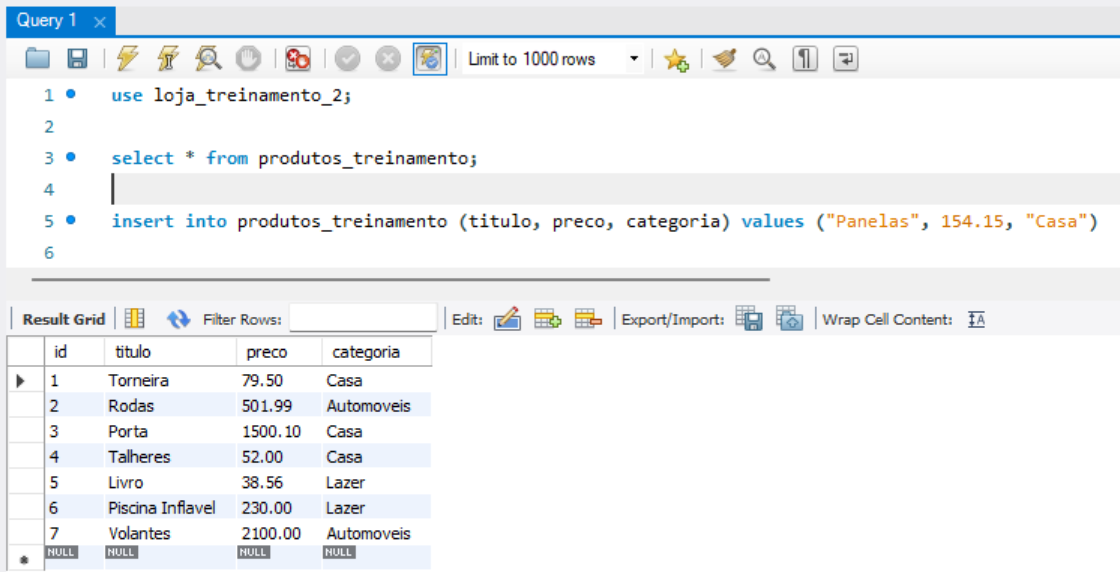

In [44]:
cursor.execute("SELECT * FROM produtos_treinamento")
cursor.fetchall()

((1, 'Torneira', Decimal('79.50'), 'Casa'),
 (2, 'Rodas', Decimal('501.99'), 'Automoveis'),
 (3, 'Porta', Decimal('1500.10'), 'Casa'),
 (4, 'Talheres', Decimal('52.00'), 'Casa'),
 (5, 'Livro', Decimal('38.56'), 'Lazer'),
 (6, 'Piscina Inflavel', Decimal('230.00'), 'Lazer'),
 (7, 'Volantes', Decimal('2100.00'), 'Automoveis'),
 (8, 'Panelas', Decimal('154.15'), 'Casa'))

**Resposta conceitual:**

A conexão acontece porque usamos a mesma porta para acessar o banco (porta: 3306), fazendo com que tanto o Python quanto o MySQL Workbench trabalhem conectados ao mesmo servidor centralizado. Logo, toda mudança feita no Python ou no Workbench é armazenada diretamente no próprio servidor de banco de dados, tornando as alterações visíveis em ambas as ferramentas assim que as alterações, criações, inserções são commitadas e a visualização é atualizada.


## Desafio final

Sem copiar diretamente os exemplos anteriores, desenvolva um pequeno cadastro para um contexto de sua escolha, como **livros, alunos, filmes, veículos ou funcionários**. Sua solução deve:

1. criar uma nova tabela;
2. possuir uma chave primária com `AUTO_INCREMENT`;
3. possuir pelo menos três atributos além do `id`;
4. inserir pelo menos cinco registros com `executemany()`;
5. executar uma consulta que mostre todos os registros;
6. executar pelo menos uma consulta com filtro;
7. utilizar `commit()` após as inserções;
8. fechar o cursor e a conexão ao final.

**Objetivo:** aplicar de forma integrada os conceitos trabalhados no notebook.


In [45]:
# Desenvolva aqui sua solução completa

cursor.execute("CREATE DATABASE IF NOT EXISTS minha_casa")
cursor.execute("USE minha_casa")

cursor.execute("""
CREATE TABLE IF NOT EXISTS quarto (
    id INT AUTO_INCREMENT PRIMARY KEY,
    movel VARCHAR(255),
    preco DECIMAL(10,2),
    material VARCHAR(100)
)
""")
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


In [46]:
dados_cliente = [
    ("Cama", 2100, "madeira"),
    ("Guarda-Roupa", 3400, "madeira"),
    ("Cabeceira", 450, "MDF"),
    ("Puff", 230, "Couro")
]

cursor.executemany("INSERT INTO quarto (movel, preco, material) VALUES (%s, %s, %s)", dados_cliente)
conn.commit()
print("Dados inseridos!")

Dados inseridos!


In [47]:
cursor.execute("SELECT * FROM quarto")
for row in cursor.fetchall():
    print(row)

(1, 'Cama', Decimal('2100.00'), 'madeira')
(2, 'Guarda-Roupa', Decimal('3400.00'), 'madeira')
(3, 'Cabeceira', Decimal('450.00'), 'MDF')
(4, 'Puff', Decimal('230.00'), 'Couro')


In [53]:
cursor.execute("SELECT * FROM quarto WHERE preco > 450.00")
for row in cursor.fetchall():
    print(row)

(1, 'Cama', Decimal('2100.00'), 'madeira')
(2, 'Guarda-Roupa', Decimal('3400.00'), 'madeira')


In [54]:
# Fecha cursor
cursor.close()

# Fecha a conexão
conn.close()